<a href="https://colab.research.google.com/github/21Tnyemo/DIRA/blob/main/NyemoRamadhani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score,
                             accuracy_score, confusion_matrix)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 160)

# Colour palette used for every chart (also reused in the slides)
INK, ACCENT, MUTED, BLUE, GREEN = '#1B2A41', '#E4572E', '#B8BCC4', '#2A6F97', '#3C8D5A'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK,
                     'ytick.color': INK, 'font.size': 11, 'axes.titleweight': 'bold',
                     'axes.titlesize': 13, 'figure.dpi': 110})
FIG_DIR = 'figs'
os.makedirs(FIG_DIR, exist_ok=True)
RESULTS = {}          # numbers that are reused in the slides

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(f'{FIG_DIR}/{name}.png', dpi=200, bbox_inches='tight')

In [2]:
# Locate the data. On Colab we mount Drive; elsewhere we fall back to local folders.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    print('Not running on Colab: using a local data folder.')

CANDIDATES = ['/content/drive/MyDrive/Final Assignment/telecom/', './telecom/', './', '/mnt/user-data/uploads/']
PATH = next(p for p in CANDIDATES if os.path.exists(os.path.join(p, 'Client.csv')))
print('Data folder:', PATH)

client = pd.read_csv(os.path.join(PATH, 'Client.csv'))
record = pd.read_csv(os.path.join(PATH, 'Record.csv'))
print('Client:', client.shape, '| Record:', record.shape)

Mounted at /content/drive
Data folder: /content/drive/MyDrive/Final Assignment/telecom/
Client: (100000, 50) | Record: (100000, 51)


In [3]:
print('Client IDs unique:', client.Customer_ID.is_unique, '| Record IDs unique:', record.Customer_ID.is_unique)
print('Same ID sets:', set(client.Customer_ID) == set(record.Customer_ID))
df = record.merge(client, on='Customer_ID', how='inner', validate='1:1')   # raises if not 1:1
print('Merged table:', df.shape)
df.head(3)

Client IDs unique: True | Record IDs unique: True
Same ID sets: True
Merged table: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.0,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.0,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.0,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0


79 numeric columns, 21 text/categorical columns
Duplicate rows: 0 | duplicate Customer_IDs: 0

Columns with any missing values: 43
numbcars            49.37 %
dwllsize            38.31 %
HHstatin            37.92 %
ownrent             33.71 %
dwlltype            31.91 %
lor                 30.19 %
income              25.44 %
adults              23.02 %
infobase            22.08 %
hnd_webcap          10.19 %
prizm_social_one     7.39 %
avg6mou              2.84 %
dtype: object


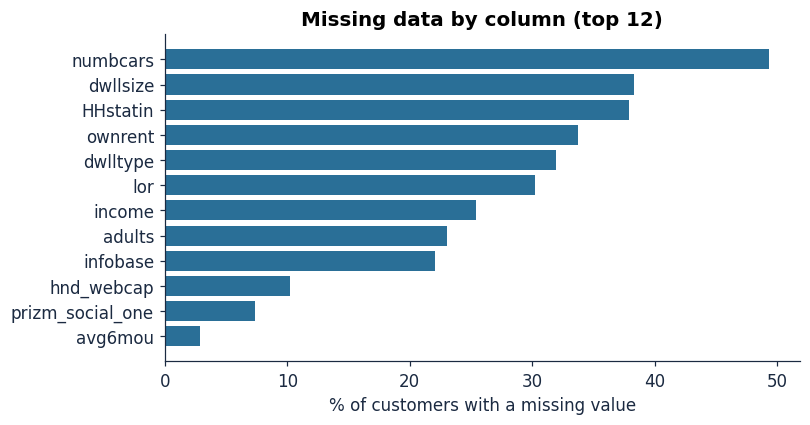

In [4]:
num_cols = df.select_dtypes(include='number').columns
cat_cols = [c for c in df.columns if c not in num_cols]
print(f'{len(num_cols)} numeric columns, {len(cat_cols)} text/categorical columns')
print('Duplicate rows:', df.duplicated().sum(), '| duplicate Customer_IDs:', df.Customer_ID.duplicated().sum())

miss = df.isna().mean().sort_values(ascending=False)
print('\nColumns with any missing values:', int((miss > 0).sum()))
print((miss[miss > 0].head(12) * 100).round(2).astype(str) + ' %')

fig, ax = plt.subplots(figsize=(7.5, 4))
top = miss[miss > 0].head(12)[::-1] * 100
ax.barh(top.index, top.values, color=BLUE)
ax.set_xlabel('% of customers with a missing value'); ax.set_title('Missing data by column (top 12)')
savefig(fig, '01_missing'); plt.show()

In [5]:
# Suspicious or surprising values: investigated, not automatically deleted
checks = {
    'eqpdays < 0 (negative handset age)':  (df.eqpdays < 0).sum(),
    'rev_Mean < 0 (net credit month)':     (df.rev_Mean < 0).sum(),
    'totmrc_Mean < 0 (net credit)':        (df.totmrc_Mean < 0).sum(),
    'avgrev <= 0':                         (df.avgrev <= 0).sum(),
    'months < 6':                          (df.months < 6).sum(),
}
print(pd.Series(checks).to_string())
print('\nTenure range (months):', df.months.min(), '-', df.months.max())
print('Handset age (days): median', df.eqpdays.median(), '| 99th pct', df.eqpdays.quantile(.99))
print('Revenue skew: mean', round(df.avgrev.mean(), 1), '| median', round(df.avgrev.median(), 1), '| 99th pct', round(df.avgrev.quantile(.99), 1))
print('\nArea values (first 8):', sorted(df.area.dropna().unique())[:8])

eqpdays < 0 (negative handset age)    133
rev_Mean < 0 (net credit month)         5
totmrc_Mean < 0 (net credit)           23
avgrev <= 0                             0
months < 6                              0

Tenure range (months): 6 - 61
Handset age (days): median 342.0 | 99th pct 1165.0
Revenue skew: mean 57.9 | median 49.9 | 99th pct 190.6

Area values (first 8): ['ATLANTIC SOUTH AREA', 'CALIFORNIA NORTH AREA', 'CENTRAL/SOUTH TEXAS AREA', 'CHICAGO AREA', 'DALLAS AREA', 'DC/MARYLAND/VIRGINIA AREA', 'GREAT LAKES AREA', 'HOUSTON AREA']


In [6]:
rate = df.churn.mean()
print(df.churn.value_counts().to_string())
print(f'\nChurn rate in this file: {rate:.1%}')
RESULTS['n_customers'] = int(len(df)); RESULTS['churn_rate_sample'] = float(rate)
RESULTS['churners'] = int(df.churn.sum()); RESULTS['avg_monthly_rev'] = float(df.avgrev.mean())

churn
0    50438
1    49562

Churn rate in this file: 49.6%


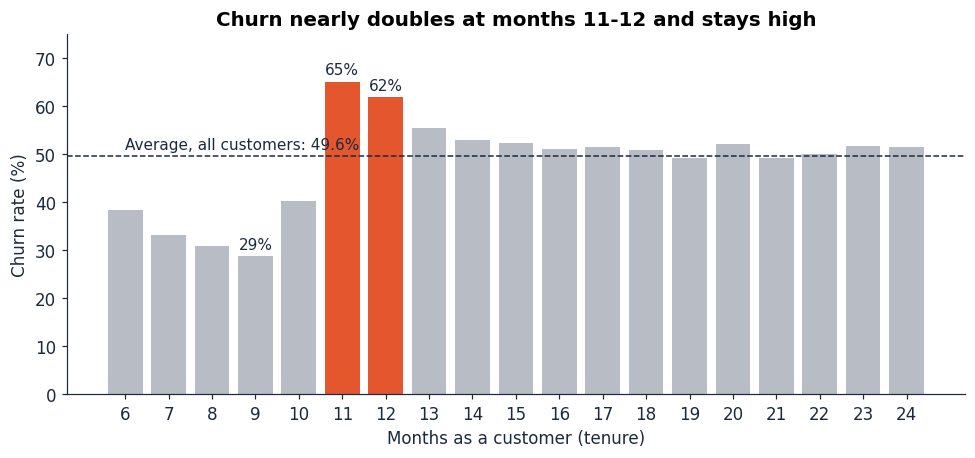

Months 6-10: 33.8% (n=18,381) | Months 11-12: 63.7% (n=14,062)


In [7]:
ten = df.groupby('months').churn.agg(['mean', 'size']).loc[6:24]
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.bar(ten.index, ten['mean'] * 100, color=[ACCENT if m in (11, 12) else MUTED for m in ten.index])
ax.axhline(rate * 100, ls='--', color=INK, lw=1)
ax.text(6, rate * 100 + 1.5, f'Average, all customers: {rate:.1%}', color=INK, fontsize=10)
for m in (9, 11, 12):
    ax.text(m, ten.loc[m, 'mean'] * 100 + 1.5, f"{ten.loc[m, 'mean']:.0%}", ha='center', fontsize=10, color=INK)
ax.set_xticks(range(6, 25)); ax.set_xlabel('Months as a customer (tenure)'); ax.set_ylabel('Churn rate (%)')
ax.set_title('Churn nearly doubles at months 11-12 and stays high'); ax.set_ylim(0, 75)
savefig(fig, '02_tenure_cliff'); plt.show()
cliff = df[df.months.between(11, 12)]; pre = df[df.months.between(6, 10)]
print(f'Months 6-10: {pre.churn.mean():.1%} (n={len(pre):,}) | Months 11-12: {cliff.churn.mean():.1%} (n={len(cliff):,})')
RESULTS['churn_m6_10'] = float(pre.churn.mean()); RESULTS['churn_m11_12'] = float(cliff.churn.mean())

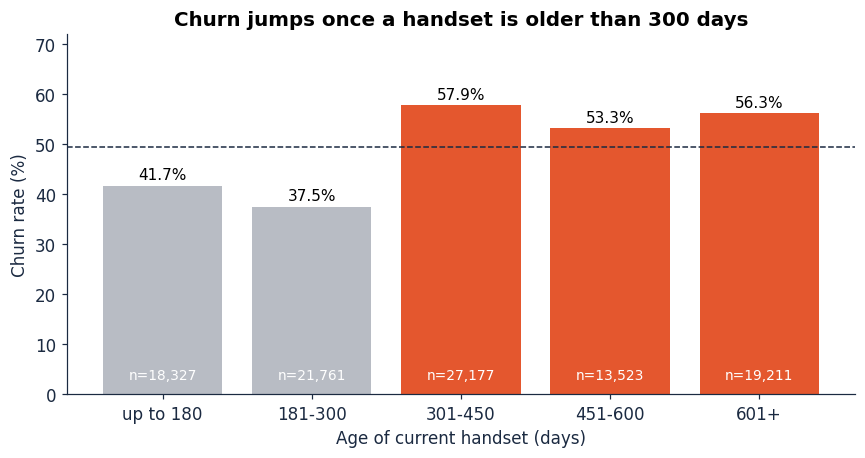

Handset > 300 days: 56.3% (n=59,911) | <= 300 days: 39.5% (n=40,088)


In [8]:
bins = [-10**9, 180, 300, 450, 600, 10**9]
labels = ['up to 180', '181-300', '301-450', '451-600', '601+']
df['eq_band'] = pd.cut(df.eqpdays, bins=bins, labels=labels)
eq = df.groupby('eq_band', observed=True).churn.agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.bar(eq.index.astype(str), eq['mean'] * 100, color=[MUTED, MUTED, ACCENT, ACCENT, ACCENT])
ax.axhline(rate * 100, ls='--', color=INK, lw=1)
for i, (m, n) in enumerate(zip(eq['mean'], eq['size'])):
    ax.text(i, m * 100 + 1.2, f'{m:.1%}', ha='center', fontsize=10)
    ax.text(i, 3, f'n={n:,}', ha='center', fontsize=9, color='white')
ax.set_xlabel('Age of current handset (days)'); ax.set_ylabel('Churn rate (%)'); ax.set_ylim(0, 72)
ax.set_title('Churn jumps once a handset is older than 300 days')
savefig(fig, '03_handset_age'); plt.show()
old, new = df[df.eqpdays > 300], df[df.eqpdays <= 300]
print(f'Handset > 300 days: {old.churn.mean():.1%} (n={len(old):,}) | <= 300 days: {new.churn.mean():.1%} (n={len(new):,})')
RESULTS.update(churn_eq_old=float(old.churn.mean()), churn_eq_new=float(new.churn.mean()), n_eq_old=int(len(old)))

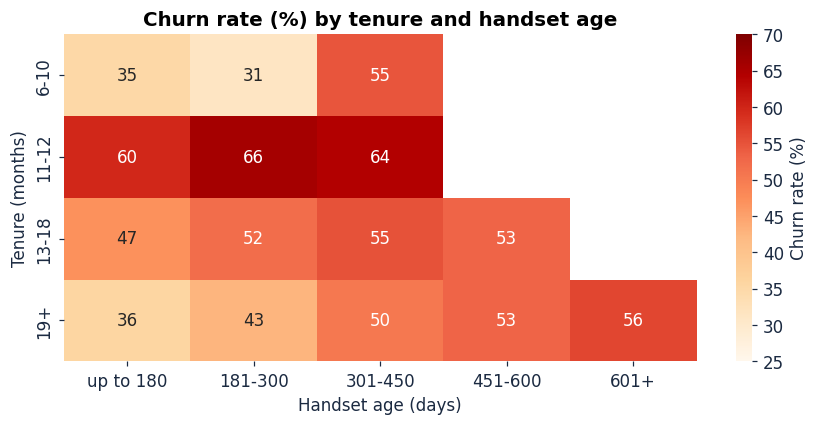

eq_band   up to 180  181-300  301-450  451-600     601+
ten_band                                               
6-10         3129.0  13843.0   1409.0      NaN      NaN
11-12        2405.0   1034.0  10623.0      NaN      NaN
13-18        4707.0   2166.0   9969.0   7320.0      NaN
19+          8086.0   4718.0   5176.0   6203.0  19211.0


In [9]:
df['ten_band'] = pd.cut(df.months, bins=[5, 10, 12, 18, 10**4], labels=['6-10', '11-12', '13-18', '19+'])
piv = df.pivot_table(index='ten_band', columns='eq_band', values='churn', aggfunc='mean', observed=True)
cnt = df.pivot_table(index='ten_band', columns='eq_band', values='churn', aggfunc='size', observed=True)
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(piv * 100, annot=True, fmt='.0f', cmap='OrRd', vmin=25, vmax=70, cbar_kws={'label': 'Churn rate (%)'}, ax=ax)
ax.set_xlabel('Handset age (days)'); ax.set_ylabel('Tenure (months)'); ax.set_title('Churn rate (%) by tenure and handset age')
savefig(fig, '04_heatmap'); plt.show()
print((cnt).to_string())

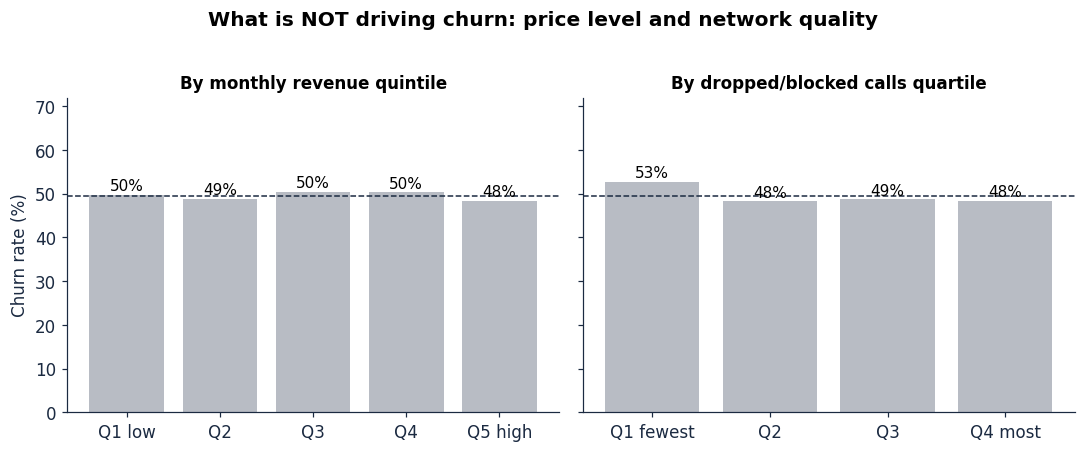

Overall call completion rate: 75.2%
       drop_blk_Mean  avgrev
churn                       
0              10.29   58.23
1               9.80   57.59


In [10]:
df['rev_q'] = pd.qcut(df.avgrev, 5, labels=['Q1 low', 'Q2', 'Q3', 'Q4', 'Q5 high'])
df['fail_q'] = pd.qcut(df.drop_blk_Mean, 4, labels=['Q1 fewest', 'Q2', 'Q3', 'Q4 most'], duplicates='drop')
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, col, title in [(axes[0], 'rev_q', 'By monthly revenue quintile'), (axes[1], 'fail_q', 'By dropped/blocked calls quartile')]:
    g = df.groupby(col, observed=True).churn.mean() * 100
    ax.bar(g.index.astype(str), g.values, color=MUTED); ax.axhline(rate * 100, ls='--', color=INK, lw=1)
    for i, v in enumerate(g.values): ax.text(i, v + 1, f'{v:.0f}%', ha='center', fontsize=10)
    ax.set_title(title, fontsize=11); ax.set_ylim(0, 72)
axes[0].set_ylabel('Churn rate (%)')
fig.suptitle('What is NOT driving churn: price level and network quality', fontweight='bold', y=1.02)
savefig(fig, '05_not_drivers'); plt.show()
comp = df.complete_Mean.sum() / df.attempt_Mean.sum()
print(f'Overall call completion rate: {comp:.1%}')
print(df.groupby('churn')[['drop_blk_Mean', 'avgrev']].mean().round(2).to_string())

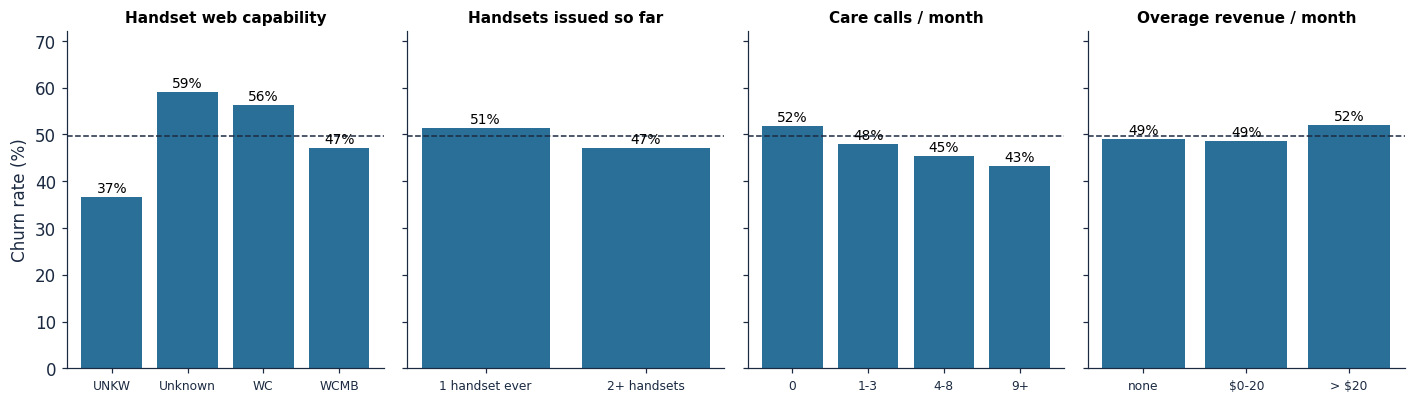

             n  churn     rev
webcap                       
UNKW       235  0.366  67.410
Unknown  10189  0.592  44.498
WC       13843  0.563  48.667
WCMB     75733  0.471  61.380


In [11]:
df['webcap'] = df.hnd_webcap.fillna('Unknown')
df['hs_history'] = np.where(df.phones == 1, '1 handset ever', '2+ handsets')
df['care_band'] = pd.cut(df.custcare_Mean, [-1, 0, 3, 8, 10**5], labels=['0', '1-3', '4-8', '9+'])
df['ovr_band'] = pd.cut(df.ovrrev_Mean, [-1, 0, 20, 10**5], labels=['none', '$0-20', '> $20'])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
for ax, col, title in [(axes[0], 'webcap', 'Handset web capability'), (axes[1], 'hs_history', 'Handsets issued so far'),
                       (axes[2], 'care_band', 'Care calls / month'), (axes[3], 'ovr_band', 'Overage revenue / month')]:
    g = df.groupby(col, observed=True).churn.agg(['mean', 'size'])
    ax.bar(g.index.astype(str), g['mean'] * 100, color=BLUE)
    ax.axhline(rate * 100, ls='--', color=INK, lw=1); ax.set_title(title, fontsize=10)
    for i, v in enumerate(g['mean'].values): ax.text(i, v * 100 + 1, f'{v:.0%}', ha='center', fontsize=9)
    ax.tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('Churn rate (%)'); axes[0].set_ylim(0, 72)
savefig(fig, '06_segments'); plt.show()
print(df.groupby('webcap').agg(n=('churn', 'size'), churn=('churn', 'mean'), rev=('avgrev', 'mean')).round(3).to_string())

In [12]:
df['annual_rev'] = df.avgrev.clip(lower=0) * 12
lost = df[df.churn == 1]
pool = df[(df.eqpdays > 300) & (df.months >= 10)]
q80 = df.avgrev.quantile(.8)
print(f'Annualised revenue of all customers in file: ${df.annual_rev.sum()/1e6:,.1f}M')
print(f'Annualised revenue of customers who churned:  ${lost.annual_rev.sum()/1e6:,.1f}M ({lost.annual_rev.sum()/df.annual_rev.sum():.0%} of total)')
print(f'Aging-handset pool (handset > 300 days & tenure >= 10 months): {len(pool):,} customers ({len(pool)/len(df):.0%}), churn {pool.churn.mean():.1%}, '
      f'{pool.churn.sum()/df.churn.sum():.0%} of all churners')
print(f'Top 20% revenue customers account for {lost[lost.avgrev >= q80].annual_rev.sum()/lost.annual_rev.sum():.0%} of churned revenue')
RESULTS.update(annual_rev_total=float(df.annual_rev.sum()), annual_rev_lost=float(lost.annual_rev.sum()),
               pool_n=int(len(pool)), pool_churn=float(pool.churn.mean()), pool_share_of_churners=float(pool.churn.sum()/df.churn.sum()))

Annualised revenue of all customers in file: $69.5M
Annualised revenue of customers who churned:  $34.3M (49% of total)
Aging-handset pool (handset > 300 days & tenure >= 10 months): 59,911 customers (60%), churn 56.3%, 68% of all churners
Top 20% revenue customers account for 38% of churned revenue


In [13]:
numcorr = df.select_dtypes(include='number').drop(columns=['Customer_ID', 'annual_rev']).corr()['churn'].drop('churn')
print('Strongest single-feature correlations with churn (absolute):')
print(numcorr.abs().sort_values(ascending=False).head(6).round(3).to_string())
print('\nMax |correlation| =', round(numcorr.abs().max(), 3), '-> no single feature is suspiciously predictive.')

Strongest single-feature correlations with churn (absolute):
eqpdays          0.113
hnd_price        0.103
totmrc_Mean      0.069
mou_Mean         0.057
mou_cvce_Mean    0.052
complete_Mean    0.052

Max |correlation| = 0.113 -> no single feature is suspiciously predictive.


In [14]:
ENG = ['eq_to_tenure', 'cliff_window', 'eq_over_300', 'mou_trend_3v6', 'rev_trend_3v6', 'mou_vs_life',
       'fail_rate', 'care_per_call', 'overage_share', 'rev_per_min']

def add_features(d):
    d = d.copy()
    d['eq_to_tenure']   = d.eqpdays / (d.months * 30.4)
    d['cliff_window']   = d.months.between(10, 12).astype(int)
    d['eq_over_300']    = (d.eqpdays > 300).astype(int)
    d['mou_trend_3v6']  = d.avg3mou / (d.avg6mou + 1)
    d['rev_trend_3v6']  = d.avg3rev / (d.avg6rev + 1)
    d['mou_vs_life']    = d.avg3mou / (d.avgmou + 1)
    d['fail_rate']      = d.drop_blk_Mean / (d.attempt_Mean + 1)
    d['care_per_call']  = d.custcare_Mean / (d.attempt_Mean + 1)
    d['overage_share']  = d.ovrrev_Mean / (d.rev_Mean.abs() + 1)
    d['rev_per_min']    = d.rev_Mean / (d.mou_Mean + 1)
    # two customers have avg6rev = -1, which makes a ratio infinite: treat infinities as missing
    d[ENG] = d[ENG].replace([np.inf, -np.inf], np.nan)
    return d

work_cols = [c for c in record.columns.tolist() + client.columns.tolist() if c in df.columns]
base = add_features(df[list(dict.fromkeys(work_cols))])
y = base['churn']
EXCLUDE = ['churn', 'Customer_ID', 'ethnic']                       # ID, target, sensitive attribute
X = base.drop(columns=EXCLUDE)
CAT = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
for c in CAT:
    X[c] = X[c].fillna('Unknown').astype('category')
NUM = [c for c in X.columns if c not in CAT]

X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.25, random_state=SEED, stratify=y_tv)
print('Features:', X.shape[1], f'({len(NUM)} numeric, {len(CAT)} categorical)')
print('Train / validation / test:', len(X_train), len(X_val), len(X_test))
print('Churn rate in each split:', round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Features: 107 (87 numeric, 20 categorical)
Train / validation / test: 60000 20000 20000
Churn rate in each split: 0.496 0.496 0.496


In [15]:
def acc_at_half(y_true, p): return accuracy_score(y_true, p >= 0.5)
rows = []

# 1) majority baseline
maj = int(y_train.mean() >= 0.5)
rows.append(['Majority class', 0.5, accuracy_score(y_val, np.full(len(y_val), maj))])

# 2) rule baseline: score = number of risk flags, classify churn if any flag is on
rule_score = (X_val.cliff_window + X_val.eq_over_300).values
rows.append(['Rule: handset>300d OR month 11-12', roc_auc_score(y_val, rule_score), accuracy_score(y_val, rule_score >= 1)])

# 3) logistic regression (preprocessing fitted on training data only)
pre = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), CAT)])
logit = make_pipeline(pre, LogisticRegression(max_iter=2000, C=0.1, random_state=SEED))
Xtr_l = X_train.copy(); Xva_l = X_val.copy()
for c in CAT: Xtr_l[c] = Xtr_l[c].astype(str); Xva_l[c] = Xva_l[c].astype(str)
logit.fit(Xtr_l, y_train)
p_logit = logit.predict_proba(Xva_l)[:, 1]
rows.append(['Logistic regression', roc_auc_score(y_val, p_logit), acc_at_half(y_val, p_logit)])

# 4) gradient boosting: three light configurations compared on the validation set
configs = {'GB shallow (depth 4)':  dict(max_iter=400, learning_rate=0.03, max_depth=4, l2_regularization=1.0),
           'GB default (depth 6)':  dict(max_iter=300, learning_rate=0.05, max_depth=6),
           'GB regularised (15 leaves)': dict(max_iter=600, learning_rate=0.02, max_leaf_nodes=15, min_samples_leaf=100, l2_regularization=2.0)}
gb_val = {}
for name, kw in configs.items():
    m = HistGradientBoostingClassifier(categorical_features='from_dtype', early_stopping=False, random_state=SEED, **kw).fit(X_train, y_train)
    pv = m.predict_proba(X_val)[:, 1]; gb_val[name] = (roc_auc_score(y_val, pv), kw)
    rows.append([name, gb_val[name][0], acc_at_half(y_val, pv)])

val_table = pd.DataFrame(rows, columns=['Model (validation set)', 'ROC-AUC', 'Accuracy']).round(4)
val_table

,Model (validation set),ROC-AUC,Accuracy
0,Majority class,0.5000,0.5044
1,Rule: handset>300d OR month 11-12,0.5913,0.5781
2,Logistic regression,0.6533,0.6149
3,GB shallow (depth 4),0.6904,0.6365
4,GB default (depth 6),0.6943,0.6394
5,GB regularised (15 leaves),0.6909,0.6384


In [16]:
best_name = max(gb_val, key=lambda k: gb_val[k][0]); best_kw = gb_val[best_name][1]
print('Selected on validation AUC:', best_name, best_kw)
# Final model: refit the chosen configuration on train + validation, then evaluate on the untouched test set ONCE.
final = HistGradientBoostingClassifier(categorical_features='from_dtype', early_stopping=False, random_state=SEED, **best_kw).fit(X_tv, y_tv)
p_test = final.predict_proba(X_test)[:, 1]

# logistic regression refit the same way for a fair test comparison
X_tv_l = X_tv.copy(); X_te_l = X_test.copy()
for c in CAT: X_tv_l[c] = X_tv_l[c].astype(str); X_te_l[c] = X_te_l[c].astype(str)
logit.fit(X_tv_l, y_tv); p_test_lr = logit.predict_proba(X_te_l)[:, 1]
rule_test = (X_test.cliff_window + X_test.eq_over_300).values
print('Final model refit on', len(X_tv), 'customers; test set has', len(X_test))

Selected on validation AUC: GB default (depth 6) {'max_iter': 300, 'learning_rate': 0.05, 'max_depth': 6}
Final model refit on 80000 customers; test set has 20000


In [17]:
auc = roc_auc_score(y_test, p_test); auc_lr = roc_auc_score(y_test, p_test_lr); auc_rule = roc_auc_score(y_test, rule_test)
acc = accuracy_score(y_test, p_test >= 0.5); pr = average_precision_score(y_test, p_test)
# 95% bootstrap interval for AUC
rng = np.random.default_rng(SEED); idx = np.arange(len(y_test)); boots = []
yt = y_test.values
for _ in range(300):
    s = rng.choice(idx, len(idx), replace=True); boots.append(roc_auc_score(yt[s], p_test[s]))
lo, hi = np.percentile(boots, [2.5, 97.5])

test_table = pd.DataFrame({
    'Model': ['Majority class', 'Rule: handset>300d OR month 11-12', 'Logistic regression', 'Gradient boosting (final)'],
    'ROC-AUC': [0.5, auc_rule, auc_lr, auc],
    'Accuracy': [max(y_test.mean(), 1 - y_test.mean()), accuracy_score(y_test, rule_test >= 1), acc_at_half(y_test, p_test_lr), acc]}).round(4)
print(test_table.to_string(index=False))
print(f'\nFINAL MODEL: HistGradientBoostingClassifier | metric: ROC-AUC | test score = {auc:.3f} (95% CI {lo:.3f}-{hi:.3f})')
print(f'Accuracy {acc:.3f} (tutorial XGBoost: 0.637) | PR-AUC {pr:.3f} (random = {y_test.mean():.3f})')
RESULTS.update(model='HistGradientBoostingClassifier', auc=float(auc), auc_lo=float(lo), auc_hi=float(hi), acc=float(acc), pr_auc=float(pr),
               auc_lr=float(auc_lr), auc_rule=float(auc_rule), acc_lr=float(acc_at_half(y_test, p_test_lr)), acc_rule=float(accuracy_score(y_test, rule_test >= 1)),
               n_train=int(len(X_train)), n_val=int(len(X_val)), n_test=int(len(X_test)), n_features=int(X.shape[1]))

                            Model  ROC-AUC  Accuracy
                   Majority class   0.5000    0.5044
Rule: handset>300d OR month 11-12   0.5929    0.5783
              Logistic regression   0.6569    0.6120
        Gradient boosting (final)   0.6951    0.6377

FINAL MODEL: HistGradientBoostingClassifier | metric: ROC-AUC | test score = 0.695 (95% CI 0.688-0.703)
Accuracy 0.638 (tutorial XGBoost: 0.637) | PR-AUC 0.685 (random = 0.496)


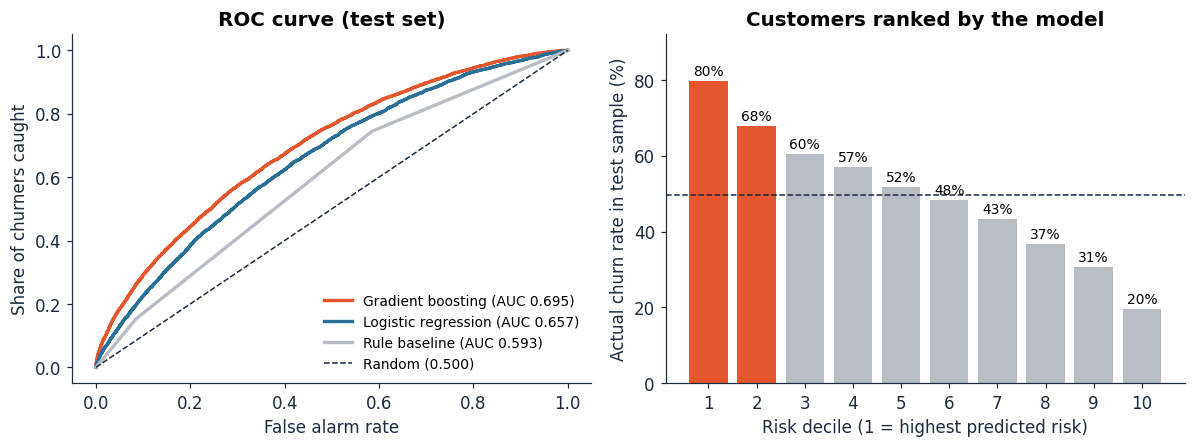

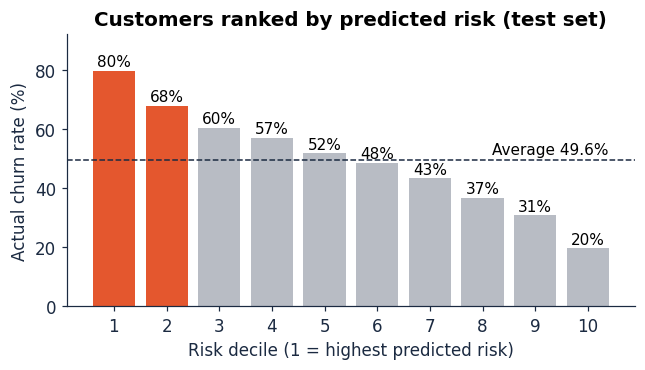

Top decile churn 79.8% vs 49.6% average (lift 1.61x); bottom decile 19.6%.
Top 20% of customers by risk contain 30% of all churners (random targeting would catch 20%).


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p, col in [('Gradient boosting', p_test, ACCENT), ('Logistic regression', p_test_lr, BLUE), ('Rule baseline', rule_test, MUTED)]:
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, color=col, lw=2.2, label=f'{name} (AUC {roc_auc_score(y_test, p):.3f})')
ax[0].plot([0, 1], [0, 1], ls='--', color=INK, lw=1, label='Random (0.500)')
ax[0].set_xlabel('False alarm rate'); ax[0].set_ylabel('Share of churners caught'); ax[0].legend(frameon=False, fontsize=9)
ax[0].set_title('ROC curve (test set)')

dec = pd.DataFrame({'y': y_test.values, 'p': p_test})
dec['decile'] = pd.qcut(dec.p.rank(method='first', ascending=False), 10, labels=range(1, 11))
lift = dec.groupby('decile', observed=True).y.mean()
ax[1].bar(lift.index.astype(int), lift.values * 100, color=[ACCENT if i <= 2 else MUTED for i in lift.index])
ax[1].axhline(y_test.mean() * 100, ls='--', color=INK, lw=1)
for i, v in zip(lift.index.astype(int), lift.values): ax[1].text(i, v * 100 + 1.5, f'{v:.0%}', ha='center', fontsize=9)
ax[1].set_xticks(range(1, 11)); ax[1].set_xlabel('Risk decile (1 = highest predicted risk)'); ax[1].set_ylabel('Actual churn rate in test sample (%)')
ax[1].set_title('Customers ranked by the model'); ax[1].set_ylim(0, 92)
savefig(fig, '07_roc_lift'); plt.show()
# Larger single-panel version of the decile chart (used in the slides)
fig2, ax2 = plt.subplots(figsize=(6, 3.5))
ax2.bar(lift.index.astype(int), lift.values * 100, color=[ACCENT if i <= 2 else MUTED for i in lift.index])
ax2.axhline(y_test.mean() * 100, ls='--', color=INK, lw=1); ax2.text(10.4, y_test.mean() * 100 + 2, f'Average {y_test.mean():.1%}', ha='right', fontsize=10)
for i, v in zip(lift.index.astype(int), lift.values): ax2.text(i, v * 100 + 1.5, f'{v:.0%}', ha='center', fontsize=10)
ax2.set_xticks(range(1, 11)); ax2.set_xlabel('Risk decile (1 = highest predicted risk)'); ax2.set_ylabel('Actual churn rate (%)'); ax2.set_ylim(0, 92)
ax2.set_title('Customers ranked by predicted risk (test set)')
savefig(fig2, '07b_lift'); plt.show()
top10 = lift.iloc[0]; top20 = dec[dec.decile.astype(int) <= 2].y.mean()
cap20 = dec[dec.decile.astype(int) <= 2].y.sum() / dec.y.sum()
print(f'Top decile churn {top10:.1%} vs {y_test.mean():.1%} average (lift {top10/y_test.mean():.2f}x); bottom decile {lift.iloc[-1]:.1%}.')
print(f'Top 20% of customers by risk contain {cap20:.0%} of all churners (random targeting would catch 20%).')
RESULTS.update(top_decile_churn=float(top10), bottom_decile_churn=float(lift.iloc[-1]), top20_capture=float(cap20), lift_by_decile=[float(v) for v in lift.values])

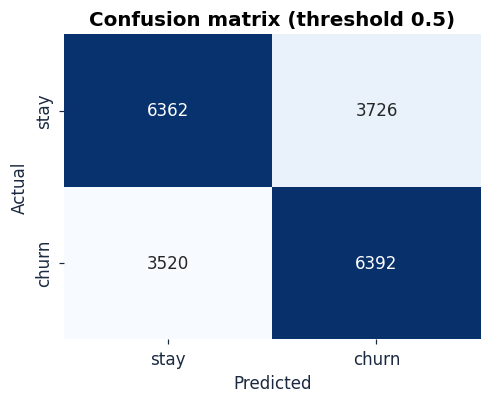

Caught 6,392 of 9,912 churners; 3,726 false alarms among 10,088 stayers.


In [19]:
cm = confusion_matrix(y_test, p_test >= 0.5)
fig, ax = plt.subplots(figsize=(4.6, 3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['stay', 'churn'], yticklabels=['stay', 'churn'], ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion matrix (threshold 0.5)')
savefig(fig, '08_confusion'); plt.show()
tn, fp, fn, tp = cm.ravel(); print(f'Caught {tp:,} of {tp+fn:,} churners; {fp:,} false alarms among {tn+fp:,} stayers.')

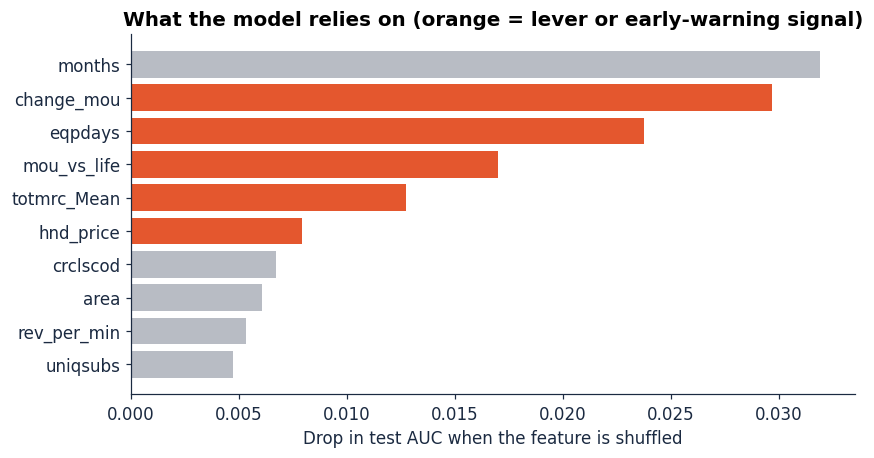

months         0.0319
change_mou     0.0297
eqpdays        0.0237
mou_vs_life    0.0170
totmrc_Mean    0.0127
hnd_price      0.0079
crclscod       0.0067
area           0.0061


In [20]:
pi = permutation_importance(final, X_test, y_test, scoring='roc_auc', n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
topk = imp.head(10)[::-1]
actionable = {'eqpdays': True, 'months': False, 'mou_Mean': False, 'change_mou': True, 'mou_vs_life': True, 'totmrc_Mean': True, 'avgqty': False, 'hnd_price': True,
              'eq_to_tenure': True, 'crclscod': False, 'uniqsubs': False, 'area': False}
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.barh(topk.index, topk.values, color=[ACCENT if actionable.get(k, False) else MUTED for k in topk.index])
ax.set_xlabel('Drop in test AUC when the feature is shuffled'); ax.set_title('What the model relies on (orange = lever or early-warning signal)')
savefig(fig, '09_importance'); plt.show()
print(imp.head(8).round(4).to_string())
RESULTS['top_features'] = {k: float(v) for k, v in imp.head(8).items()}

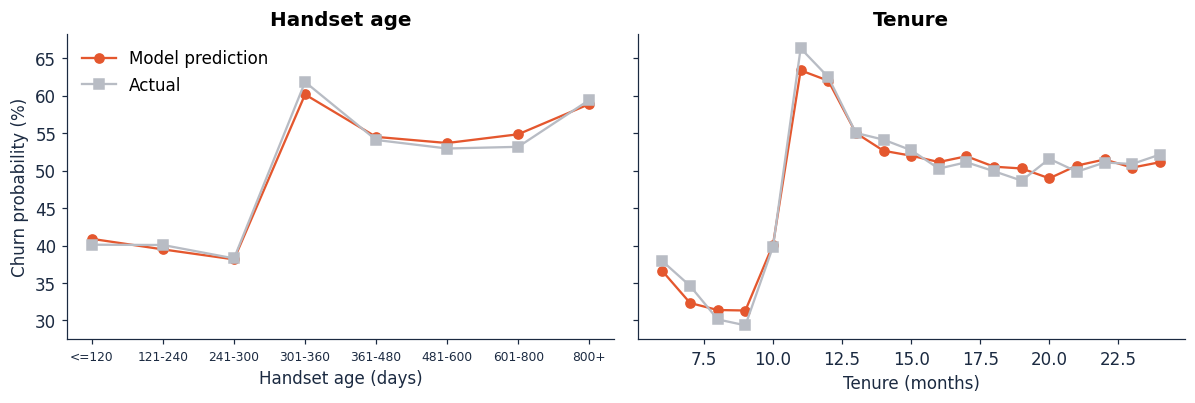

In [21]:
# Shape of the learned relationship: average predicted churn by handset age and tenure (test set)
t = X_test.copy(); t['p'] = p_test; t['y'] = y_test.values
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
g1 = t.groupby(pd.cut(t.eqpdays, [-10**9, 120, 240, 300, 360, 480, 600, 800, 10**9]), observed=True)[['p', 'y']].mean()
ax[0].plot(range(len(g1)), g1.p * 100, marker='o', color=ACCENT, label='Model prediction'); ax[0].plot(range(len(g1)), g1.y * 100, marker='s', color=MUTED, label='Actual')
ax[0].set_xticks(range(len(g1))); ax[0].set_xticklabels(['<=120', '121-240', '241-300', '301-360', '361-480', '481-600', '601-800', '800+'], fontsize=8)
ax[0].set_xlabel('Handset age (days)'); ax[0].set_ylabel('Churn probability (%)'); ax[0].legend(frameon=False); ax[0].set_title('Handset age')
g2 = t.groupby('months')[['p', 'y']].mean().loc[6:24]
ax[1].plot(g2.index, g2.p * 100, marker='o', color=ACCENT); ax[1].plot(g2.index, g2.y * 100, marker='s', color=MUTED)
ax[1].set_xlabel('Tenure (months)'); ax[1].set_title('Tenure')
savefig(fig, '10_shape'); plt.show()

In [22]:
# Robustness checks (retrain on train, score on validation): is one feature doing all the work? does excluding 'ethnic' cost accuracy?
def val_auc(cols, extra=None):
    Xa = X_train[cols]; Xb = X_val[cols]
    m = HistGradientBoostingClassifier(categorical_features='from_dtype', early_stopping=False, random_state=SEED, **best_kw).fit(Xa, y_train)
    return roc_auc_score(y_val, m.predict_proba(Xb)[:, 1])
all_cols = list(X.columns)
r_all = val_auc(all_cols)
r_noeq = val_auc([c for c in all_cols if c not in ('eqpdays', 'eq_to_tenure', 'eq_over_300', 'cliff_window', 'months')])
r_noeng = val_auc([c for c in all_cols if c not in ENG])
# add the sensitive column back to quantify what excluding it costs
Xe_tr = X_train.copy(); Xe_va = X_val.copy(); Xe_tr['ethnic'] = base.loc[X_train.index, 'ethnic'].fillna('Unknown').astype('category'); Xe_va['ethnic'] = base.loc[X_val.index, 'ethnic'].fillna('Unknown').astype('category')
me = HistGradientBoostingClassifier(categorical_features='from_dtype', early_stopping=False, random_state=SEED, **best_kw).fit(Xe_tr, y_train)
r_eth = roc_auc_score(y_val, me.predict_proba(Xe_va)[:, 1])
print(pd.Series({'All features (final set)': r_all, 'Without tenure & handset-age features': r_noeq, 'Without engineered features': r_noeng,
                 'If sensitive attribute `ethnic` were included': r_eth}).round(4).to_string())
RESULTS.update(auc_val_all=float(r_all), auc_val_no_lifecycle=float(r_noeq), auc_val_no_eng=float(r_noeng), auc_val_with_ethnic=float(r_eth))

All features (final set)                         0.6943
Without tenure & handset-age features            0.6732
Without engineered features                      0.6922
If sensitive attribute `ethnic` were included    0.6933


In [23]:
# Does the model work equally well across customer groups? (test set)
t['tenure_band'] = pd.cut(t.months, [5, 10, 12, 18, 10**4], labels=['6-10', '11-12', '13-18', '19+'])
t['value_tier'] = pd.qcut(t.avgrev, [0, .5, .8, 1], labels=['Standard (bottom 50%)', 'High (50-80%)', 'Top (top 20%)'])
seg = []
for col in ['tenure_band', 'value_tier']:
    for k, g in t.groupby(col, observed=True):
        seg.append([col, k, len(g), g.y.mean(), roc_auc_score(g.y, g.p)])
pd.DataFrame(seg, columns=['Segment type', 'Segment', 'n', 'Churn rate', 'AUC']).round(3)

,Segment type,Segment,n,Churn rate,AUC
0,tenure_band,6-10,3601,0.340,0.713
1,tenure_band,11-12,2811,0.647,0.668
2,tenure_band,13-18,4901,0.526,0.651
3,tenure_band,19+,8687,0.494,0.669
4,value_tier,Standard (bottom 50%),10003,0.498,0.698
5,value_tier,High (50-80%),5999,0.498,0.700
6,value_tier,Top (top 20%),3998,0.487,0.677


In [24]:
PI_SAMPLE = float(df.churn.mean())
PI_REAL   = 0.02          # assumption: real monthly churn (about 0.9-1.1% reported by the big three [1][2][3], ~2% estimated for cable operators [3]; 1-3% tested below)
MARGIN, HORIZON = 0.50, 12
SCALE = 100_000 / len(X_test)                       # express results per 100,000 customers
ACTIONS = {'A: digital nudge': dict(cost=1.0, save=0.10),
           'B: agent call + credit': dict(cost=8.0, save=0.20),
           'C: handset offer': dict(cost=33.0, save=0.30)}

def prior_shift(p, pi_real):
    # Multiply every customer's odds by one constant k, chosen (bisection) so that the AVERAGE re-weighted
    # churn probability equals the assumed real churn rate. Ranking is unchanged; only the level changes.
    odds = p / (1 - p); lo, hi = 1e-6, 1.0
    for _ in range(60):
        k = np.sqrt(lo * hi); q = k * odds / (1 + k * odds)
        lo, hi = (k, hi) if q.mean() < pi_real else (lo, k)
    return k * odds / (1 + k * odds)

rev = X_test.avgrev.clip(lower=0).values

def run_policy(pi_real=PI_REAL, effect_mult=1.0, fixed_assign=None):
    p_real = prior_shift(p_test, pi_real)
    V = rev * MARGIN * HORIZON
    ev = np.column_stack([p_real * a['save'] * effect_mult * V - a['cost'] for a in ACTIONS.values()])
    if fixed_assign is None:
        best = ev.argmax(axis=1); treat = ev.max(axis=1) > 0
    else:
        best, treat = fixed_assign
    idx = np.arange(len(best))
    save = np.array([a['save'] for a in ACTIONS.values()])[best]; cost = np.array([a['cost'] for a in ACTIONS.values()])[best]
    saved = (p_real * save * effect_mult)[treat]; protected = (p_real * save * effect_mult * rev * 12)[treat]
    net = (p_real * save * effect_mult * V - cost)[treat]
    out = dict(contacts=treat.sum() * SCALE, spend=cost[treat].sum() * SCALE, saved=saved.sum() * SCALE,
               revenue_protected=protected.sum() * SCALE, net=net.sum() * SCALE,
               gross=(p_real * save * effect_mult * V)[treat].sum() * SCALE,
               churners_in_contacted=p_real[treat].sum() * SCALE, total_churners=p_real.sum() * SCALE,
               lanes={k: int(((best == i) & treat).sum() * SCALE) for i, k in enumerate(ACTIONS)}, assign=(best, treat))
    return out

base_case = run_policy()
total_contacts = base_case['contacts']
print(f'BASE CASE per 100,000 customers, per monthly cycle (real churn {PI_REAL:.0%}, margin {MARGIN:.0%}, horizon {HORIZON} months)')
print(f"  Customers contacted:     {base_case['contacts']:>9,.0f}  ({base_case['contacts']/1000:.1f}% of base)   lanes: {base_case['lanes']}")
print(f"  Program spend:           ${base_case['spend']:>9,.0f}")
print(f"  Expected churners saved: {base_case['saved']:>9,.0f}   (of ~{base_case['total_churners']:,.0f} churners/month; {base_case['churners_in_contacted']:,.0f} are inside the contacted group)")
print(f"  Revenue protected (12m): ${base_case['revenue_protected']:>9,.0f}")
print(f"  Net value (after cost):  ${base_case['net']:>9,.0f} per month cycle")

BASE CASE per 100,000 customers, per monthly cycle (real churn 2%, margin 50%, horizon 12 months)
  Customers contacted:        17,695  (17.7% of base)   lanes: {'A: digital nudge': 17430, 'B: agent call + credit': 255, 'C: handset offer': 10}
  Program spend:           $   19,800
  Expected churners saved:        78   (of ~2,000 churners/month; 746 are inside the contacted group)
  Revenue protected (12m): $   77,876
  Net value (after cost):  $   19,138 per month cycle


In [25]:
# Comparison: why the model (and the value ranking) matters. Same lanes, different targeting rules.
p_real = prior_shift(p_test, PI_REAL); V = rev * MARGIN * HORIZON
def blanket(a):   # contact EVERYONE with one lane
    return ((p_real * a['save'] * V - a['cost']).sum()) * SCALE
rows = [['Contact everyone with lane A (digital)', blanket(ACTIONS['A: digital nudge'])],
        ['Contact everyone with lane B (agent call)', blanket(ACTIONS['B: agent call + credit'])],
        ['Contact everyone with lane C (handset offer)', blanket(ACTIONS['C: handset offer'])]]
# Same number of contacts chosen at random (lane A) vs by the model's value ranking
n_t = int(total_contacts / SCALE); rng = np.random.default_rng(SEED)
rand_net = np.mean([(p_real[s] * 0.10 * V[s] - 1.0).sum() * SCALE for s in [rng.choice(len(p_real), n_t, replace=False) for _ in range(50)]])
rows.append([f'Random {n_t*SCALE:,.0f} customers, lane A only', rand_net])
rows.append(['Retention Radar (model + value ranking + lanes)', base_case['net']])
cmp_tbl = pd.DataFrame(rows, columns=['Targeting rule', 'Net value per 100k customers per cycle ($)']).round(0)
cmp_tbl['Net value per 100k customers per cycle ($)'] = cmp_tbl['Net value per 100k customers per cycle ($)'].map(lambda v: f'{v:,.0f}')
print(cmp_tbl.to_string(index=False))

                                 Targeting rule Net value per 100k customers per cycle ($)
         Contact everyone with lane A (digital)                                    -29,822
      Contact everyone with lane B (agent call)                                   -659,644
   Contact everyone with lane C (handset offer)                                 -3,089,466
           Random 17,695 customers, lane A only                                     -5,314
Retention Radar (model + value ranking + lanes)                                     19,138


Monthly net value per 100,000 customers ($) by real churn rate (rows) and share of assumed effect actually achieved (columns):
      25%   50%    75%   100%   125%
1%  -3155  -600   1955   4510   7065
2% -10066  -331   9403  19138  28872
3% -18858  1365  21587  41810  62032

Break-even: the plan still pays back if the actions achieve at least this share of the assumed effect:
  real churn 1%: 56%
  real churn 2%: 51%
  real churn 3%: 48%


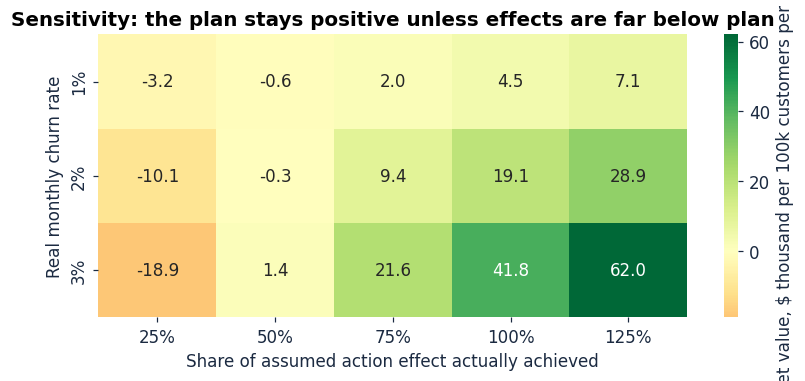

In [26]:
# Sensitivity: how wrong can the assumptions be? (1) real churn rate x (2) how well the actions really work.
# Policy is fixed at what we would plan for each churn rate; 'realised effect' scales the assumed effects.
pis = [0.01, 0.02, 0.03]; realised = [0.25, 0.5, 0.75, 1.0, 1.25]
grid = pd.DataFrame(index=[f'{p:.0%}' for p in pis], columns=[f'{int(r*100)}%' for r in realised], dtype=float)
breakeven = {}
for pi_ in pis:
    plan = run_policy(pi_real=pi_)
    for r in realised:
        grid.loc[f'{pi_:.0%}', f'{int(r*100)}%'] = run_policy(pi_real=pi_, effect_mult=r, fixed_assign=plan['assign'])['net']
    breakeven[pi_] = plan['spend'] / plan['gross']
print('Monthly net value per 100,000 customers ($) by real churn rate (rows) and share of assumed effect actually achieved (columns):')
print(grid.round(0).astype(int).to_string())
print('\nBreak-even: the plan still pays back if the actions achieve at least this share of the assumed effect:')
for k, v in breakeven.items(): print(f'  real churn {k:.0%}: {v:.0%}')
fig, ax = plt.subplots(figsize=(7.5, 3.6))
sns.heatmap(grid / 1000, annot=True, fmt='.1f', cmap='RdYlGn', center=0, cbar_kws={'label': 'Net value, $ thousand per 100k customers per cycle'}, ax=ax)
ax.set_xlabel('Share of assumed action effect actually achieved'); ax.set_ylabel('Real monthly churn rate')
ax.set_title('Sensitivity: the plan stays positive unless effects are far below plan')
savefig(fig, '11_sensitivity'); plt.show()
RESULTS['sens_grid'] = {r: {c: float(grid.loc[r, c]) for c in grid.columns} for r in grid.index}
RESULTS['breakeven'] = {f'{k:.0%}': float(v) for k, v in breakeven.items()}

In [27]:
ANNUAL_FACTOR = 6      # 12 monthly cycles x 50% haircut for re-contacting persistent-risk customers and offer fatigue (assumption)
annual_net = base_case['net'] * ANNUAL_FACTOR
annual_saved = base_case['saved'] * ANNUAL_FACTOR
base_rev_month = df.avgrev.mean() * 100_000
print(f'Planning view per 100,000 customers: ~${annual_net:,.0f} net value per year and ~{annual_saved:,.0f} customers retained,')
print(f'  = {annual_net/(base_rev_month*12):.1%} of annual revenue (${base_rev_month*12/1e6:,.1f}M); spend ${base_case["spend"]*ANNUAL_FACTOR:,.0f} per year.')
print(f'  Retained margin per $1 spent: ${(base_case["net"] + base_case["spend"])/base_case["spend"]:.2f} (net gain ${base_case["net"]/base_case["spend"]:.2f} per $1)')
ACQ_COST = 300     # assumption: cost to replace a lost customer; an older study [6] puts it above $300
upside = annual_saved * ACQ_COST
print(f'  Upside NOT included in the figures above: avoided replacement cost ~ ${upside:,.0f} per year (assumption: ${ACQ_COST} per customer)')
RESULTS.update(base=dict(contacts=float(base_case['contacts']), spend=float(base_case['spend']), saved=float(base_case['saved']),
                         revenue_protected=float(base_case['revenue_protected']), net=float(base_case['net']), lanes=base_case['lanes'],
                         total_churners=float(base_case['total_churners'])),
               annual_net=float(annual_net), annual_saved=float(annual_saved), upside=float(upside), annual_rev_per_100k=float(base_rev_month * 12),
               compare={r[0]: float(v) for r, v in zip(rows, [x[1] for x in rows])}, pi_real=PI_REAL, margin=MARGIN, horizon=HORIZON)

Planning view per 100,000 customers: ~$114,828 net value per year and ~471 customers retained,
  = 0.2% of annual revenue ($69.5M); spend $118,800 per year.
  Retained margin per $1 spent: $1.97 (net gain $0.97 per $1)
  Upside NOT included in the figures above: avoided replacement cost ~ $141,287 per year (assumption: $300 per customer)


In [28]:
# How many customers are needed per group to detect a 20% relative churn reduction (two-sided 5% test, 80% power)?
from math import ceil
z_a, z_b = 1.96, 0.84
preal_tr = prior_shift(p_test, PI_REAL)
rows = []
for label, mask in [('All contacted customers (lanes A-C, ~18% of base)', base_case['assign'][1]),
                    ('Highest-risk decile', dec.decile.astype(int).values <= 1)]:
    p1 = float(preal_tr[mask].mean()); p2 = p1 * 0.8
    n = ceil((z_a + z_b) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p1 - p2) ** 2)
    rows.append([label, f'{p1:.1%}', f'{p2:.1%}', f'{n:,}'])
print(pd.DataFrame(rows, columns=['Eligible group', 'Control monthly churn', 'Target (-20%)', 'Customers needed per arm']).to_string(index=False))
RESULTS['pilot_n_per_arm'] = rows[1][3]

                                   Eligible group Control monthly churn Target (-20%) Customers needed per arm
All contacted customers (lanes A-C, ~18% of base)                  4.2%          3.4%                    8,042
                              Highest-risk decile                  5.9%          4.7%                    5,652


In [29]:
with open('results.json', 'w') as f: json.dump(RESULTS, f, indent=1, default=str)
print('Saved key numbers to results.json')

Saved key numbers to results.json
